### pour Vision Transformer avec pooling attentionnel pour la reconnaissance des expressions faciales, par Xue et al et la comparaison entre les deux architectures:cnn classique de Modi et Al et vision transformers

In [1]:
!unzip dataset.zip -d .#decompresser le dataset,j'ai utilisé google colab

Streaming output truncated to the last 5000 lines.
  inflating: ./train/sad/Training_65242339.jpg  
  inflating: ./train/sad/Training_65267116.jpg  
  inflating: ./train/sad/Training_65275626.jpg  
  inflating: ./train/sad/Training_6529266.jpg  
  inflating: ./train/sad/Training_65329617.jpg  
  inflating: ./train/sad/Training_65338712.jpg  
  inflating: ./train/sad/Training_65338797.jpg  
  inflating: ./train/sad/Training_65387162.jpg  
  inflating: ./train/sad/Training_65404494.jpg  
  inflating: ./train/sad/Training_65426218.jpg  
  inflating: ./train/sad/Training_65430136.jpg  
  inflating: ./train/sad/Training_65437377.jpg  
  inflating: ./train/sad/Training_6545735.jpg  
  inflating: ./train/sad/Training_65463385.jpg  
  inflating: ./train/sad/Training_65473985.jpg  
  inflating: ./train/sad/Training_65502829.jpg  
  inflating: ./train/sad/Training_65505359.jpg  
  inflating: ./train/sad/Training_65508578.jpg  
  inflating: ./train/sad/Training_65516023.jpg  
  inflating: ./train

In [1]:
# ---  IMPORTATIONS ---
import os # Permet de gérer les chemins de fichiers et dossiers sur le système
import time # Permet de mesurer précisément le temps d'entraînement de chaque époque
import numpy as np # Bibliothèque de calcul matriciel 
import matplotlib.pyplot as plt # Permet d'afficher les courbes et la matrice de confusion 
import torch 
import torch.nn as nn 
import torch.optim as optim # pour les algorithmes d'optimisation (AdamW)
from torch.utils.data import DataLoader # Gère le découpage des données en mini-lots (batches)
from torchvision import datasets, transforms 
import timm # Bibliothèque de référence contenant les architectures Vision Transformers (MobileViT, ViT)
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay # Métriques 
import cv2 # OpenCV : utilisé pour la détection de visage en temps réel via webcam
from PIL import Image # Python Imaging Library : permet de manipuler les images au format PIL
from sklearn.metrics import accuracy_score, f1_score


In [4]:
# ---  PRÉTRAITEMENT DU DATASET ---
DATA_DIR = "./dataset" # Chemin vers le dossier contenant 'train' et 'val'
BATCH_SIZE = 64 # Lots de 64 images 

# on Choisis "vit" après (MobileViT inspiré de Xue et al)
MODEL_CHOICE = "vit"

# Résolution adaptée au modèle : 48x48 (natif FER-2013) pour le CNN, 128x128 pour le Transformer léger
IMG_SIZE = 48 if MODEL_CHOICE == "cnn" else 128

# 1. Pipeline de transformations pour l'entraînement (Data Augmentation pour éviter le surapprentissage)
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Redimensionne l'image à la taille optimale 
    transforms.RandomHorizontalFlip(p=0.5), # Symétrie miroir horizontale (50% de chance) : conserve l'émotion 
    transforms.RandomRotation(degrees=15), # Rotation aléatoire de -15° à +15° pour simuler l'inclinaison de la tête
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Variation légère de luminosité/contraste
    transforms.ToTensor(), # Convertit l'image (0-255) en Tenseur PyTorch normalisé entre 0.0 et 1.0
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Standardisation statistique ImageNet
])

# 2. Pipeline pour la validation (aucune modification aléatoire pour évaluer le modèle sur des images réelles)
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Redimensionne uniquement
    transforms.ToTensor(), # Convertit en Tenseur
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Applique la même standardisation
])

# 3. Chargement des images depuis les dossiers
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=train_transforms)
val_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "val"), transform=val_transforms)

# 4. Création des DataLoaders 
#(num_workers=0 évite les surcharges de mémoire sur cpu sous JupyterLab mais là,on est sur gpu donc 2 est mieux adapté)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_dataset.classes # Récupère automatiquement la liste des 7 émotions (noms des dossiers)
print(f"Modèle sélectionné : {MODEL_CHOICE.upper()} | Résolution : {IMG_SIZE}x{IMG_SIZE}")
print(f"Classes détectées ({len(class_names)}) : {class_names}")
print(f"Images d'entraînement : {len(train_dataset)} | Images de validation : {len(val_dataset)}")

Modèle sélectionné : VIT | Résolution : 128x128
Classes détectées (7) : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Images d'entraînement : 28709 | Images de validation : 7178


In [6]:
# ARCHITECTURE 1 : Réseau de Neurones Convolutif (Inspiré de Modi & Bohara, 2021 et Goodfellow et al., 2016)
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(EmotionCNN, self).__init__() # Initialise la classe parente nn.Module de PyTorch

        # Extracteur de caractéristiques locales (contours des yeux, courbure de la bouche, sourcils)
        self.features = nn.Sequential(
            # Bloc 1 : 3 canaux RGB -> 32 cartes de caractéristiques
            nn.Conv2d(3, 32, kernel_size=3, padding=1), # Convolution 3x3 conservant la taille spatiale (padding=1)
            nn.BatchNorm2d(32), # Normalisation par lot : stabilise et accélère l'apprentissage (Ioffe & Szegedy, 2015)
            nn.ReLU(inplace=True), # Fonction d'activation Rectified Linear Unit : introduit la non-linéarité
            nn.MaxPool2d(kernel_size=2, stride=2), # Sous-échantillonnage : divise largeur et hauteur par 2 (48 -> 24)

            # Bloc 2 : 32 -> 64 filtres
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Résolution passe de 24x24 à 12x12

            # Bloc 3 : 64 -> 128 filtres
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Résolution passe de 12x12 à 6x6

            # Bloc 4 : 128 -> 256 filtres
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)) # Global Average Pooling : compresse chaque carte 6x6 en une moyenne 1x1
        )

        # Classifieur final 
        self.classifier = nn.Sequential(
            nn.Flatten(), # Transforme le tenseur (Batch, 256, 1, 1) en vecteur plat (Batch, 256)
            nn.Dropout(p=0.5), # Régularisation : éteint aléatoirement 50% des neurones 
            nn.Linear(256, 128), # Couche entièrement connectée de 256 vers 128 neurones
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes) # Couche de sortie produisant les 7 scores bruts (logits)
        )

    def forward(self, x):
        x = self.features(x) # Passe l'image dans les couches convolutives
        x = self.classifier(x) # Passe les caractéristiques extraites dans le classifieur
        return x

# ARCHITECTURE 2 : Vision Transformer (Inspiré de Xue et al., 2021 et Mehta & Rastegari, 2022)
def build_vit_cpu_model(num_classes=7, pretrained=True):
    # 'mobilevit_xxs' combine des convolutions locales et des blocs Transformers d'attention globale
    # Il est ~65 fois plus léger qu'un ViT classique
    model = timm.create_model('mobilevit_xxs', pretrained=pretrained, num_classes=num_classes)
    return model

In [12]:
# ---ENTRAÎNEMENT DU VISION TRANSFORMER (MobileViT) ---

# Forcer l'utilisation du GPU (CUDA)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device == torch.device("cuda")) # Doit afficher True si le GPU est bien activé

EPOCHS = 12#comme pour CNN

# 1. Initialisation du modèle et transfert sur le GPU
if MODEL_CHOICE == "cnn":
    model = EmotionCNN(num_classes=len(class_names)).to(device)
    learning_rate = 1e-3
else:
    model = build_vit_cpu_model(num_classes=len(class_names), pretrained=True).to(device)
    learning_rate = 3e-4  # Taux plus faible pour affiner les poids pré-entraînés

# 2. Définition de la fonction de perte et de l'optimiseur
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

# 3. Initialisation du suivi des performances
history = {'train_loss': [], 'val_acc': []}
best_acc = 0.0

print(f"Début de l'entraînement de {MODEL_CHOICE.upper()} sur GPU ({EPOCHS} époques)...")

for epoch in range(EPOCHS):
    start_time = time.time()

    # --- PHASE D'ENTRAÎNEMENT ---
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        # Envoi des données sur le GPU
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad()               # Remise à zéro des gradients
        outputs = model(images)             # Prédiction (Forward pass)
        loss = criterion(outputs, labels)   # Calcul de l'erreur
        loss.backward()                     # Calcul des gradients (Backpropagation)
        optimizer.step()                    # Mise à jour des poids

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    # --- PHASE DE VALIDATION ---
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():  # Désactive les gradients pour économiser la mémoire
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    val_acc = np.mean(np.array(all_preds) == np.array(all_labels))
    elapsed = time.time() - start_time

    history['train_loss'].append(epoch_loss)
    history['val_acc'].append(val_acc)

    print(f"Époque [{epoch+1}/{EPOCHS}] ({elapsed:.0f}s) | Perte Train: {epoch_loss:.4f} | Précision Val: {val_acc*100:.2f}%")

    # Sauvegarde automatique du meilleur modèle
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), f"models/best_{MODEL_CHOICE}_emotion.pth")

print(f"\nEntraînement terminé sur GPU ! Meilleure précision : {best_acc*100:.2f}%")

True
Début de l'entraînement de VIT sur GPU (12 époques)...
Époque [1/12] (115s) | Perte Train: 1.3677 | Précision Val: 55.95%
Époque [2/12] (115s) | Perte Train: 1.0999 | Précision Val: 59.89%
Époque [3/12] (115s) | Perte Train: 1.0114 | Précision Val: 60.45%
Époque [4/12] (114s) | Perte Train: 0.9561 | Précision Val: 62.59%
Époque [5/12] (115s) | Perte Train: 0.9194 | Précision Val: 63.89%
Époque [6/12] (118s) | Perte Train: 0.8769 | Précision Val: 63.74%
Époque [7/12] (115s) | Perte Train: 0.8460 | Précision Val: 64.75%
Époque [8/12] (115s) | Perte Train: 0.8123 | Précision Val: 64.32%
Époque [9/12] (120s) | Perte Train: 0.7894 | Précision Val: 66.23%
Époque [10/12] (120s) | Perte Train: 0.7686 | Précision Val: 66.37%
Époque [11/12] (124s) | Perte Train: 0.7382 | Précision Val: 66.20%
Époque [12/12] (119s) | Perte Train: 0.7141 | Précision Val: 66.20%

Entraînement terminé sur GPU ! Meilleure précision : 66.37%


Rapport de classification détaillé :

              precision    recall  f1-score   support

       angry       0.55      0.66      0.60       958
     disgust       0.66      0.50      0.57       111
        fear       0.59      0.36      0.44      1024
       happy       0.82      0.91      0.86      1774
     neutral       0.62      0.61      0.61      1233
         sad       0.54      0.52      0.53      1247
    surprise       0.72      0.83      0.77       831

    accuracy                           0.66      7178
   macro avg       0.64      0.63      0.63      7178
weighted avg       0.65      0.66      0.65      7178

Graphiques sauvegardés avec succès sous : resultats_vit_emotion.png


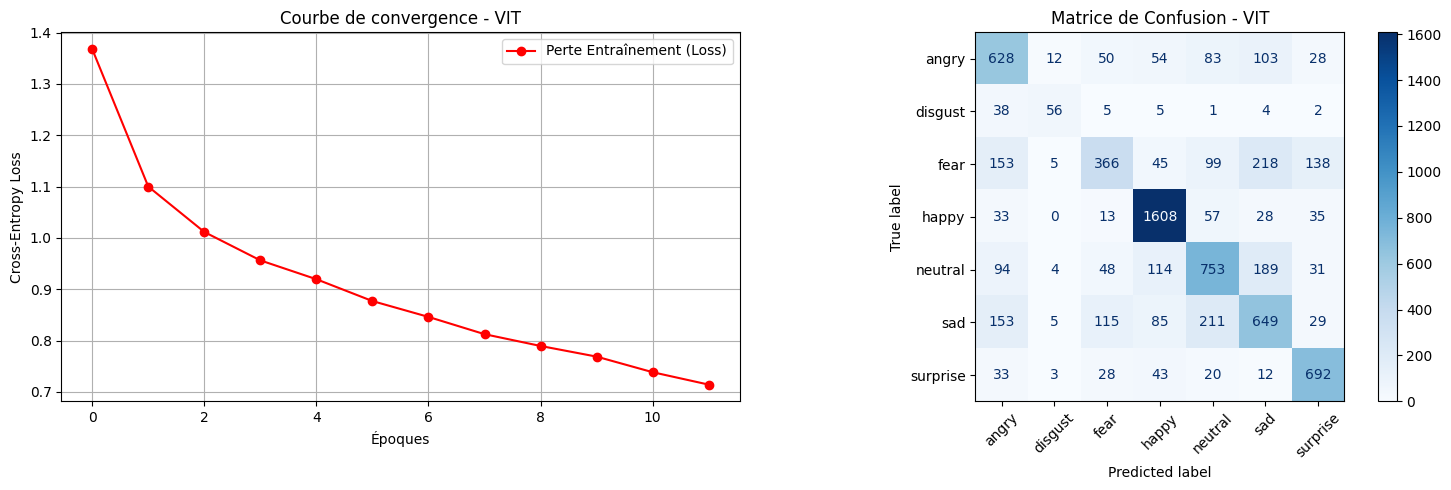

In [13]:
# --- ANALYSE DES RÉSULTATS ---

# 1. Affichage du rapport complet (Précision, Rappel, F1-Score par émotion)
print("Rapport de classification détaillé :\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 2. Traçage des graphiques
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique de gauche : Évolution de la perte d'entraînement
axes[0].plot(history['train_loss'], label='Perte Entraînement (Loss)', color='red', marker='o')
axes[0].set_title(f'Courbe de convergence - {MODEL_CHOICE.upper()}')
axes[0].set_xlabel('Époques')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True)

# Graphique de droite : Matrice de confusion (montre quelles émotions sont confondues entre elles)
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=axes[1], cmap='Blues', xticks_rotation=45)
axes[1].set_title(f'Matrice de Confusion - {MODEL_CHOICE.upper()}')

plt.tight_layout()
#SAUVEGARDE
nom_fichier = f"results/resultats_{MODEL_CHOICE}_emotion.png"
plt.savefig(nom_fichier, dpi=300, bbox_inches='tight')
print(f"Graphiques sauvegardés avec succès sous : {nom_fichier}")
plt.show()

In [8]:
# ---TESTE: DÉTECTION EN DIRECT VIA WEBCAM ---
# Note : Une fenêtre externe OpenCV va s'ouvrir. Appuyez sur la touche 'q' de votre clavier pour la fermer.
#  Création de la structure vide du modèle en mémoire (indispensable après un redémarrage du Kernel)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if MODEL_CHOICE == "cnn":
    model = EmotionCNN(num_classes=len(class_names)).to(device)
else:
    model = build_vit_cpu_model(num_classes=len(class_names), pretrained=False).to(device)

#Chargement des poids entraînés depuis le fichier sauvegardé:"best_vit_emotion.pth" obtenue avant
model.load_state_dict(torch.load(f"best_{MODEL_CHOICE}_emotion.pth", map_location=device))
model.eval()

#  Chargement du détecteur de visages Haar Cascade (Viola & Jones, 2001) inclus dans OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Démarrage de la caméra (0 = webcam intégrée par défaut)
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read() # Capture une image (frame) du flux vidéo
    if not ret:
        print("Erreur d'accès à la webcam.")
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) # Convertit en niveaux de gris pour accélérer la détection de visage
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5) # Détecte les visages (x, y, largeur, hauteur)

    for (x, y, w, h) in faces:
        face_roi = frame[y:y+h, x:x+w] # Découpe uniquement la zone du visage (Region of Interest)
        face_rgb = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB) # Convertit l'ordre des couleurs BGR (OpenCV) vers RGB (PyTorch)
        pil_img = Image.fromarray(face_rgb) # Transforme le tableau NumPy en image PIL

        # Applique les transformations de validation et ajoute la dimension de lot (1, 3, IMG_SIZE, IMG_SIZE)
        input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(input_tensor) # Prédiction instantanée sur CPU
            probabilities = torch.nn.functional.softmax(outputs, dim=1) # Convertit les logits en probabilités (0 à 1)
            confidence, predicted_idx = torch.max(probabilities, 1) # Récupère l'émotion la plus probable et son score

        label = f"{class_names[predicted_idx.item()]} ({confidence.item()*100:.1f}%)"

        # Dessine un cadre vert autour du visage et affiche l'émotion détectée
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(frame, label, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    cv2.imshow('Reconnaissance des Emotions - CPU (Appuyez sur Q pour quitter)', frame)

    # Attend 1 ms et vérifie si la touche 'q' est pressée
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release() # Libère la webcam
cv2.destroyAllWindows() # Ferme la fenêtre OpenCV

Évaluation du CNN en cours...
Évaluation du MobileViT en cours...

Critère d évaluation         | EmotionCNN (48x48) | MobileViT (128x128)
Précision globale (Accuracy) |            59.85% |             66.37%
Score F1 moyen (Macro)       |            50.53% |             63.01%
Temps d inférence CPU / img  |            4.93 ms |            18.57 ms

Graphique comparatif sauvegardé sous : comparaison_cnn_vs_vit.png


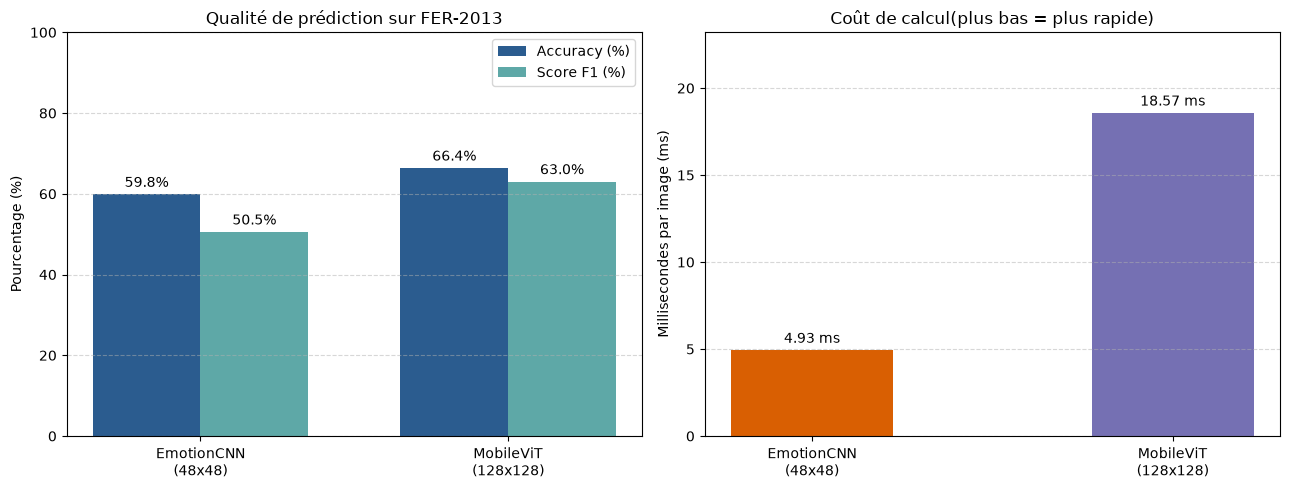

In [11]:
# ---  COMPARAISON SCIENTIFIQUE CNN vs MOBILEVIT ---



VAL_DIR = "dataset/val"

def evaluer_modele(choix, img_size):
    """Évalue un modèle sauvegardé (.pth) sur le jeu de test et mesure sa latence CPU."""

    # 1. Transformations adaptées à la résolution du modèle (48x48 pour CNN, 128x128 pour ViT)
    eval_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    val_dataset = datasets.ImageFolder(root=VAL_DIR, transform=eval_transform)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    # 2. Reconstruction de l'architecture et chargement des poids entraînés
    if choix == "cnn":
        net = EmotionCNN(num_classes=len(class_names)).to(device)
    else:
        net = build_vit_cpu_model(num_classes=len(class_names), pretrained=False).to(device)

    net.load_state_dict(torch.load(f"best_{choix}_emotion.pth", map_location=device))
    net.eval()

    # 3. Inférence sur toutes les images de test et mesure du temps CPU
    all_preds, all_targets = [], []
    start_time = time.time()

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = net(images.to(device))
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.numpy())

    total_time = time.time() - start_time

    # 4. Calcul des métriques
    acc = accuracy_score(all_targets, all_preds) * 100
    f1 = f1_score(all_targets, all_preds, average='macro') * 100
    ms_per_img = (total_time / len(val_dataset)) * 1000

    return acc, f1, ms_per_img

# --- EXÉCUTION DE LA COMPARAISON ---
print("Évaluation du CNN en cours...")
acc_cnn, f1_cnn, temps_cnn = evaluer_modele("cnn", 48)

print("Évaluation du MobileViT en cours...")
acc_vit, f1_vit, temps_vit = evaluer_modele("vit", 128)

# --- AFFICHAGE DU TABLEAU RÉCAPITULATIF ---
print("\n" + "="*68)
print(f"{'Critère d évaluation':<28} | {'EmotionCNN (48x48)':<18} | {'MobileViT (128x128)':<18}")
print("="*68)
print(f"{'Précision globale (Accuracy)':<28} | {acc_cnn:>16.2f}% | {acc_vit:>17.2f}%")
print(f"{'Score F1 moyen (Macro)':<28} | {f1_cnn:>16.2f}% | {f1_vit:>17.2f}%")
print(f"{'Temps d inférence CPU / img':<28} | {temps_cnn:>15.2f} ms | {temps_vit:>16.2f} ms")
print("="*68)

# --- GÉNÉRATION ET SAUVEGARDE DU GRAPHIQUE COMPARATIF ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
modeles = ['EmotionCNN\n(48x48)', 'MobileViT\n(128x128)']

# Graphique 1 : Précision et Score F1
x = np.arange(len(modeles))
width = 0.35
rects1 = ax1.bar(x - width/2, [acc_cnn, acc_vit], width, label='Accuracy (%)', color='#2b5c8f')
rects2 = ax1.bar(x + width/2, [f1_cnn, f1_vit], width, label='Score F1 (%)', color='#5ea8a7')

ax1.set_xticks(x)
ax1.set_xticklabels(modeles)
ax1.set_ylim(0, 100)
ax1.set_ylabel('Pourcentage (%)')
ax1.set_title('Qualité de prédiction sur FER-2013')
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Affichage des valeurs exactes au-dessus des barres
ax1.bar_label(rects1, fmt='%.1f%%', padding=3)
ax1.bar_label(rects2, fmt='%.1f%%', padding=3)

# Graphique 2 : Latence CPU (ms par image)
rects3 = ax2.bar(modeles, [temps_cnn, temps_vit], color=['#d95f02', '#7570b3'], width=0.45)
ax2.set_ylabel('Millisecondes par image (ms)')
ax2.set_title('Coût de calcul(plus bas = plus rapide)')
ax2.set_ylim(0, max(temps_cnn, temps_vit) * 1.25)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.bar_label(rects3, fmt='%.2f ms', padding=3)

plt.tight_layout()
plt.savefig("comparaison_cnn_vs_vit.png", dpi=300, bbox_inches='tight')
print("\nGraphique comparatif sauvegardé sous : comparaison_cnn_vs_vit.png")
plt.show()